variance by pca1, pca2: [0.26179749 0.21640127]
total variance exaplined by 2 components: 0.47819876073856576


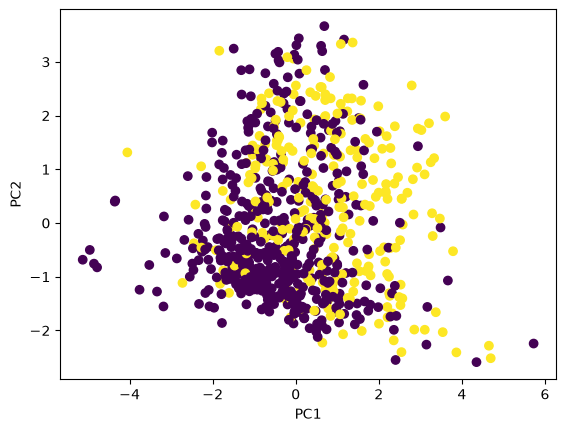

variance by pca1, pca2, pca3: [0.26179749 0.21640127 0.12870373]
cumulative variance explained: [0.26179749 0.47819876 0.60690249]
variance added by pc3: 0.12870373364801915


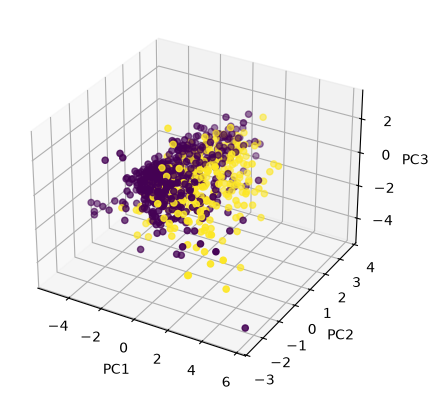

In [1]:
# 8
# principle component analysis on a dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

file = "https://raw.githubusercontent.com/rahulbhadani/Datasets/refs/heads/master/Diabetes/diabetes.csv"
df = pd.read_csv(file)
x = df.drop(columns="Outcome")
y = df["Outcome"]

# dimensionality reduction ising PCA

# 1 
# problem doesnt tell us whether to standardize or not, in some code examples you did and some you did not
# so ill assume it is fine to do so 
scaler = StandardScaler().fit(x)
x_scaled = scaler.transform(x)

pca = PCA(n_components=2)
# perform pca 
x_pca = pca.fit_transform(x_scaled) 

# variance explained by two components
print("variance by pca1, pca2:", pca.explained_variance_ratio_)
print("total variance exaplined by 2 components:", pca.explained_variance_ratio_.sum())
# the results tell us pc1 explains 26.18% and pc2 explains 21.64% of the variance
# together they explain 47.82% of the total variance

# 2
# plot of two principle components
plt.scatter(x_pca[:,0], x_pca[:,1], c=y)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()
# the two classes (diabetic and non-diabetic) are semi-distinguishable; it is clear from the graph
# that there is major overlap between the two classes, however, the diabetic points (c1)
# tend to trend toward higher pc1 values while non-diabetic points (c0) trend towards lower
# pc1 values. This trend does not set strict boundaries between classes from what I can see.

# 3
pca3 = PCA(n_components=3)
x_pca3 = pca3.fit_transform(x_scaled)
print("variance by pca1, pca2, pca3:", pca3.explained_variance_ratio_)
print("cumulative variance explained:", np.cumsum(pca3.explained_variance_ratio_))
print("variance added by pc3:", pca3.explained_variance_ratio_[2])
# pc1 = 26.18%, pc2 = 21.64%, pc3 = 12.87%, cumulative = 60.69%
# the first two components did not change, pc3 adds 12.87% to the variance
# this still leaves an uncaptured 39% of total variance

# 4
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x_pca3[:, 0], x_pca3[:, 1], x_pca3[:, 2], c=y)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
plt.show()
# the classes are slightly more distinguishable in 3d then 2d. the third component
# adds more information, but the two classes generally overlap heavily and do not seem seperable.
# pc3 explains 13% more of the variance which explains why there is not much of a difference in parts 3 and 4
# 

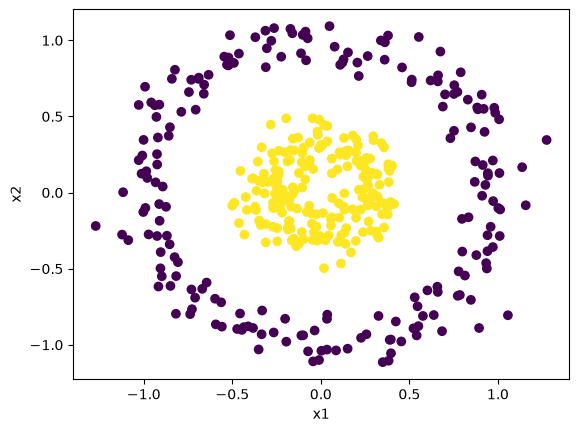

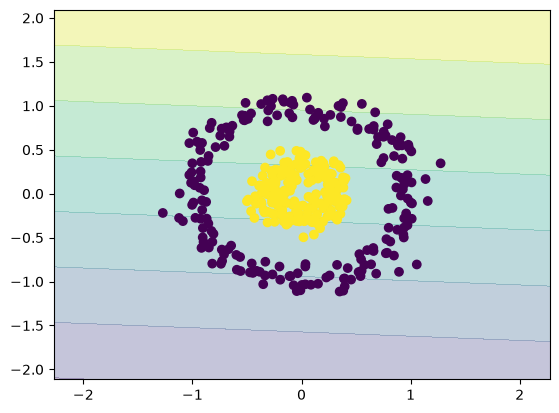

0.6725


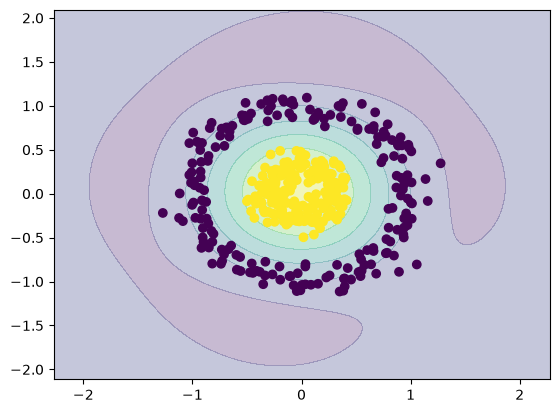

1.0
1.0


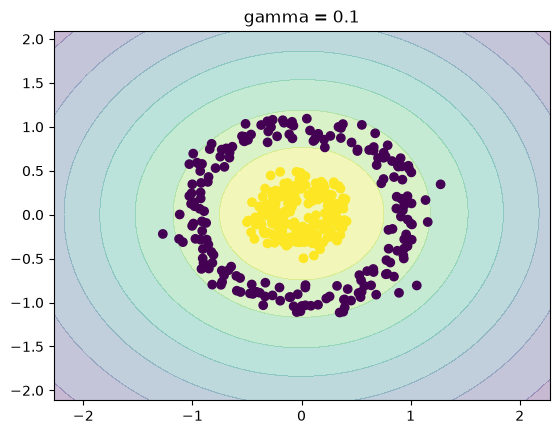

1.0


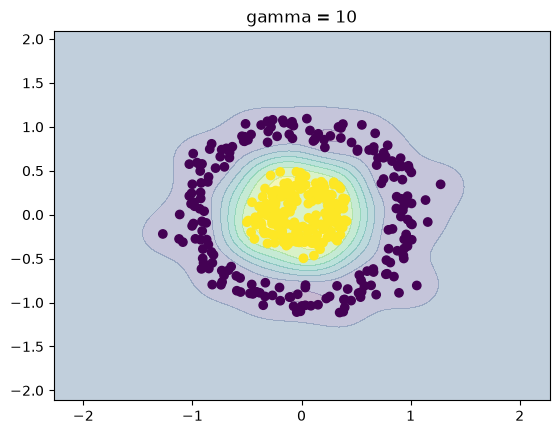

In [2]:

# 9
# transforming data with kernels and SVM
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay

# 1
from sklearn.datasets import make_circles
X, y = make_circles(n_samples=400, noise=0.1, factor=0.3, random_state=1)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()
# linear SVM would fail here because the two classes are obviously not linearly seperable

# 2
clf_linear = SVC(kernel="linear").fit(X,y)
DecisionBoundaryDisplay.from_estimator(clf_linear, X, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()
print(accuracy_score(y, clf_linear.predict(X)))
# the accuracy score is 0.6725, which confirms that a straight line cannot seperate the inner vs outer ring

# 3
clf_rbf = SVC(kernel="rbf", gamma=1.0).fit(X,y)
DecisionBoundaryDisplay.from_estimator(clf_rbf, X, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()
print(accuracy_score(y, clf_rbf.predict(X)))
# the accuracy is 1.0, from the documentation scikit learn describes the kernel function as
# k(xi,xj) = exp( ( -d*(xi,xj)^2 ) / (2(l)^2) )
# SVC parameterises this kernerl w/ gamma = 1 / (2 l^2)
# this measures the similarity between two points via dot product in higher-dimensional feature space
# the ring and inner cluster become linearly seperable
# a flat boundary maps back to a closed circular boundary in 2d space. (this is the trick)

# 4
# gamma = 0.1
clf_g01 = SVC(kernel="rbf", gamma=0.1).fit(X, y)
print(accuracy_score(y, clf_g01.predict(X)))
DecisionBoundaryDisplay.from_estimator(clf_g01, X, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("gamma = 0.1")
plt.show()

# gamma = 10
clf_g10 = SVC(kernel="rbf", gamma=10).fit(X, y)
print(accuracy_score(y, clf_g10.predict(X)))
DecisionBoundaryDisplay.from_estimator(clf_g10, X, alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("gamma = 10")
plt.show()

# gamma controls the distance of the training points
# smaller gamma means a wider influence, a wide boundary that can underfit values if necessary
# a large gamma means a tigher influence, a small boundary that can overfit values that are too large
# both are still 1.0 accuracy, because they are easily seperable
# the difference is only the shape of the boundary


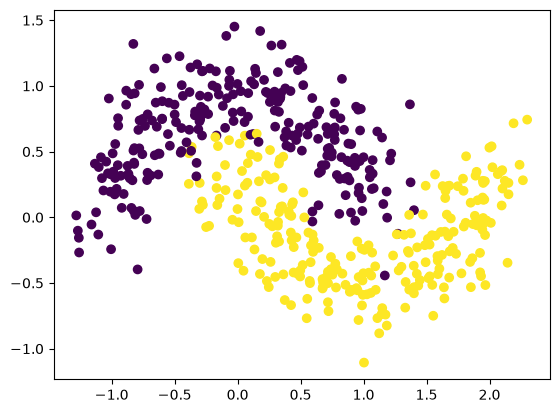

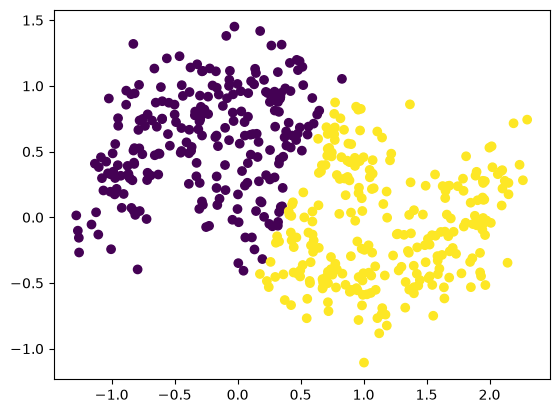

adjusted rand index: 0.25252044170139215
v-measure: 0.1924122881970769
shilhouette score: 0.4727330565154631
calinski-harabasz index: 688.3406108514203


In [3]:
# 10
# k-means
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import v_measure_score
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score

# half moon dataset, 500 samples, noise = 0.2
X, y = make_moons(n_samples=500, noise=0.2, random_state=0)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

# k-means w/ 2 clusters
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
labels = kmeans.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.show()

# evaluate cluster quality
ari = adjusted_rand_score(y, labels)
vm = v_measure_score(y, labels)
sil = silhouette_score(X, labels)
ch = calinski_harabasz_score(X, labels)

print(f"adjusted rand index:", ari)
print(f"v-measure:", vm)
print(f"shilhouette score:", sil)
print(f"calinski-harabasz index:", ch)

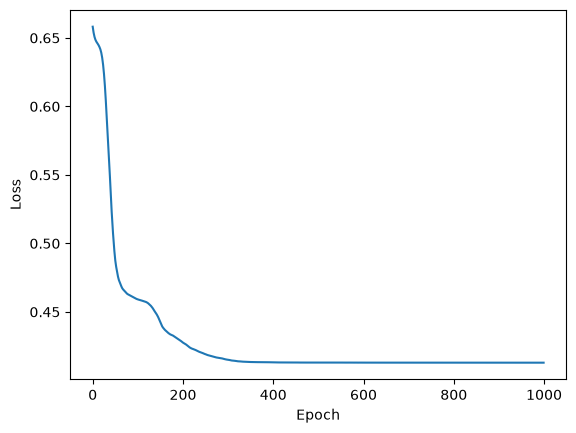

W1126 21:59:11.372000 250984 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::nms
W1126 21:59:11.373000 250984 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_align
W1126 21:59:11.373000 250984 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::roi_pool
W1126 21:59:11.373000 250984 torch/onnx/_internal/exporter/_registration.py:107] torchvision is not installed. Skipping torchvision::deform_conv2d


[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Sequential([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
1


In [ ]:
# 11
# classification with neural network
from prettyjoey.model.neuralnet import TorchNet
import inspect
file = "https://raw.githubusercontent.com/rahulbhadani/Datasets/refs/heads/master/Diabetes/diabetes.csv"
df = pd.read_csv(file)
X = df.drop(columns="Outcome")
y = df["Outcome"]

net = TorchNet(input_dim=X.shape[1], output_dim=y.nunique())
net.train(X, y)
net.plot_loss()
net.save_onnx("torchnet.onnx")
net.load_onnx("torchnet.onnx")

print(net.predict([7, 149, 73, 94, 94, 32, 0.672, 45]))
